# 10 · Robustez a imágenes "feas": ruido, desenfoque y baja resolución — H6 (EMA) vs H7 (sin EMA)

El profesor advirtió que el EMA puede hacer al modelo frágil con imágenes "feas" y pidió un pipeline robusto.
Aquí se mide, **solo en validación (15 casos)**, cuánto pierde cada modelo cuando la imagen viene dañada.
**No entrena y no toca test.**

| Prueba | Qué simula |
|---|---|
| `noise=10` | ruido leve (≈ 70 HU), tomografía de baja dosis |
| `noise=25` | ruido fuerte (≈ 175 HU), imagen muy granulada |
| `blur=1.5` | desenfoque (movimiento del paciente, reconstrucción suave) |
| `lowres=2.5` | baja resolución (cortes gruesos / escáner viejo) |

Tiempo en T4: ~12 min por corrida × 8 corridas ≈ 1.6 h. Cada resultado se guarda apenas termina.

In [28]:
!nvidia-smi -L || echo "SIN GPU: activa la GPU antes de seguir"

GPU 0: Tesla T4 (UUID: GPU-c68e8e7e-e17e-dce7-5e57-8b1b69e2078f)
GPU 1: Tesla T4 (UUID: GPU-b0c242cf-4c57-6825-58e8-f9b48a441473)


## 1. Datos, código y modelos

Usa el dataset **`pengwin-h7`** (caché, código y H6). **H7** se busca en `/kaggle/working/resultados` (si es la misma sesión
del notebook 09) o en cualquier dataset agregado (subir `h7_auggeo_rot35_canon_aumm_noema_w32_e60_s42.pth` como nueva versión de `pengwin-h7`).

In [29]:
import os, glob, zipfile, shutil, csv, json
def buscar(patron, raiz="/kaggle/input"):
    return sorted(glob.glob(f"{raiz}/**/{patron}", recursive=True))
CARPETA = "/kaggle/working/resultados"; os.makedirs(CARPETA, exist_ok=True)
H6 = (buscar("h6_auggeo_rot35_canon_ema_w32_e60_s42.pth") or ["NO ENCONTRADO"])[0]
H7 = (buscar("h7_auggeo_rot35_canon_aumm_noema_w32_e60_s42.pth", "/kaggle/working")
      or buscar("h7_auggeo_rot35_canon_aumm_noema_w32_e60_s42.pth") or ["NO ENCONTRADO"])[0]
os.chdir("/kaggle/working")
if not os.path.exists("repo"):
    src = buscar("src/aumento_fisico.py")
    if src:
        shutil.copytree(os.path.dirname(os.path.dirname(src[0])), "repo")
    else:
        z = buscar("codigo_pengwin.zip"); assert z, "No encontré el código"
        with zipfile.ZipFile(z[0]) as f: f.extractall("repo_zip")
        shutil.move(glob.glob("repo_zip/*")[0], "repo")
os.chdir("/kaggle/working/repo")
if not os.path.exists("data/cache/s10/cache_384"):
    idx = [p for p in buscar("index.csv") if os.path.isdir(os.path.join(os.path.dirname(p), "cache_384"))]
    os.makedirs("data/cache", exist_ok=True)
    if idx:
        os.symlink(os.path.dirname(idx[0]), "data/cache/s10")
    else:
        z = buscar("cache_s10_todo.zip"); assert z, "No encontré el caché"
        with zipfile.ZipFile(z[0]) as f: f.extractall(".")
CD = "data/cache/s10/cache_384"
print("H6:", H6); print("H7:", H7)
assert os.path.exists(H6) and os.path.exists(H7), "Falta H6 o H7 (ver instrucciones arriba)"
!pip -q install SimpleITK scikit-image

H6: /kaggle/input/datasets/mariavalencia30/pengwin-h7/h6_auggeo_rot35_canon_ema_w32_e60_s42.pth
H7: /kaggle/working/H7_final_pengwin/h7_auggeo_rot35_canon_aumm_noema_w32_e60_s42.pth


## 2. Agregar `noise=` y `blur=` a la prueba de estrés (si el código aún no los tiene)

In [31]:
PARCHE = r'''
"""Agrega a apply_stress (src/evaluate_volumes.py) dos deformaciones de calidad de imagen:

  noise=S  ruido gaussiano de desviación S (en niveles de gris 0-255 del caché; 1 nivel ≈ 7 HU)
  blur=S   desenfoque gaussiano de desviación S píxeles

Solo afectan la imagen (la etiqueta no cambia). El ruido usa una semilla fija por bloque de cortes,
así la prueba es reproducible. Se combinan con las demás claves: p. ej. --stress noise=10,blur=1
Uso (desde la raíz del repo):  python aplicar_estres_ruido.py src/evaluate_volumes.py
"""
import sys
from pathlib import Path

ruta = Path(sys.argv[1] if len(sys.argv) > 1 else "src/evaluate_volumes.py")
s = ruta.read_text()
if 'opts.get("noise"' in s:
    sys.exit("Ya tiene noise/blur; no hago nada.")
ancla = '        out_i.append(x[:, 0].round().clamp(0, 255).numpy().astype(np.uint8))'
if ancla not in s:
    sys.exit("No encontré el punto de anclaje en apply_stress. No se guardó nada.")
nuevo = """        if opts.get("blur", 0.0) > 0:      # desenfoque gaussiano separable, solo imagen
            sigma = opts["blur"]
            radio = max(1, int(round(3 * sigma)))
            t = torch.arange(-radio, radio + 1, dtype=torch.float32)
            k = torch.exp(-0.5 * (t / sigma) ** 2); k = k / k.sum()
            x = F.conv2d(F.pad(x, (radio, radio, 0, 0), mode="reflect"), k.view(1, 1, 1, -1))
            x = F.conv2d(F.pad(x, (0, 0, radio, radio), mode="reflect"), k.view(1, 1, -1, 1))
        if opts.get("noise", 0.0) > 0:     # ruido gaussiano reproducible, solo imagen
            g = torch.Generator().manual_seed(1234 + start)
            x = x + torch.randn(x.shape, generator=g) * opts["noise"]
"""
s = s.replace(ancla, nuevo + ancla, 1)
s = s.replace("``lowres=2.5`` (reduce filas por ese factor y vuelve a ampliar).",
              "``lowres=2.5`` (reduce filas por ese factor y vuelve a ampliar), ``noise=10`` (ruido gaussiano,\n    niveles de gris 0-255) y ``blur=1.5`` (desenfoque gaussiano en píxeles).", 1)
compile(s, str(ruta), "exec")
ruta.write_text(s)
print(f"OK: --stress noise=S y blur=S disponibles en {ruta}")

'''
open('/kaggle/working/aplicar_estres_ruido.py', 'w').write(PARCHE)
!python /kaggle/working/aplicar_estres_ruido.py src/evaluate_volumes.py

Ya tiene noise/blur; no hago nada.


## 3. Cómo se ven las imágenes dañadas (un corte de validación)

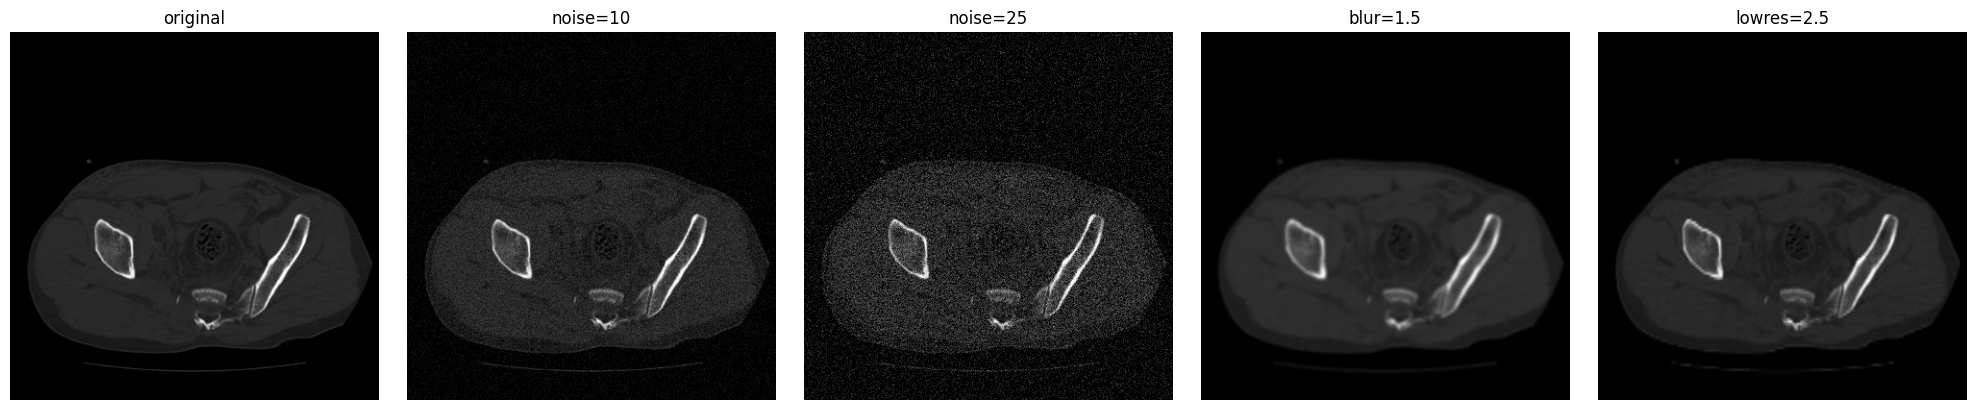

In [32]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "src")
import importlib, evaluate_volumes; importlib.reload(evaluate_volumes)
from build_case_cache import load_case_cache
from aumento_fisico import mm_por_pixel
caso = load_case_cache(CD, "019", canonical=True)
k = len(caso["images"]) // 2
pruebas = ["", "noise=10", "noise=25", "blur=1.5", "lowres=2.5"]
fig, ax = plt.subplots(1, len(pruebas), figsize=(4 * len(pruebas), 4))
for a, p in zip(ax, pruebas):
    img = evaluate_volumes.apply_stress(caso["images"][k:k+1], caso["labels"][k:k+1], p, mm_por_pixel(caso))[0][0] if p else caso["images"][k]
    a.imshow(img, cmap="gray"); a.set_title(p or "original"); a.axis("off")
plt.tight_layout(); plt.savefig(f"{CARPETA}/ejemplos_ruido.png", dpi=90); plt.show()

## 4. Evaluación (validación, con TTA)

In [33]:
PRUEBAS = ["noise=10", "noise=25", "blur=1.5", "lowres=2.5"]
for etiqueta, ruta in [("H7", H7), ("H6", H6)]:
    for prueba in PRUEBAS:
        salida = f"{CARPETA}/ruido_{etiqueta}_{prueba.replace('=', '')}.json"
        if os.path.exists(salida):
            print("ya existe:", salida); continue
        print(f"\n===== {etiqueta} · {prueba} =====")
        !python src/evaluate_volumes.py --checkpoint "{ruta}" --cache-dir {CD} --split val --tta --stress {prueba} --output "{salida}" 2>&1 | grep -E "casos de|caso |Guardado|rror"


===== H7 · noise=10 =====
15 casos de val | dispositivo cuda | TTA=True | segundo pase=False | normalizar=False
  1/15 caso 014: 298 cortes (41 s)
  2/15 caso 019: 350 cortes (88 s)
  3/15 caso 024: 350 cortes (135 s)
  4/15 caso 027: 313 cortes (177 s)
  5/15 caso 033: 365 cortes (228 s)
  6/15 caso 044: 409 cortes (287 s)
  7/15 caso 050: 326 cortes (332 s)
  8/15 caso 057: 341 cortes (377 s)
  9/15 caso 060: 333 cortes (423 s)
  10/15 caso 067: 369 cortes (472 s)
  11/15 caso 077: 350 cortes (519 s)
  12/15 caso 078: 388 cortes (571 s)
  13/15 caso 087: 312 cortes (614 s)
  14/15 caso 095: 257 cortes (649 s)
  15/15 caso 099: 286 cortes (688 s)
Guardado: /kaggle/working/resultados/ruido_H7_noise10.json

===== H7 · noise=25 =====
15 casos de val | dispositivo cuda | TTA=True | segundo pase=False | normalizar=False
  1/15 caso 014: 298 cortes (41 s)
  2/15 caso 019: 350 cortes (89 s)
  3/15 caso 024: 350 cortes (136 s)
  4/15 caso 027: 313 cortes (176 s)
  5/15 caso 033: 365 cortes (

## 5. Tabla: cuánto pierde cada modelo

In [45]:
import json
for p in ["noise10", "noise25", "blur1.5"]:
    r = json.load(open(f"{CARPETA}/ruido_H7_{p}.json"))["subsets"]["todo"]
    print(f"H7 {p:8s}  F1 {r['classification_f1_macro']:.3f}  mAP50 {r['detection_map50']:.3f}  Dice {r['segmentation_dice_macro']:.3f}  Dice fragmento {r['instance_dice_matched']:.3f}")

H7 noise10   F1 0.879  mAP50 0.730  Dice 0.825  Dice fragmento 0.654
H7 noise25   F1 0.517  mAP50 0.224  Dice 0.383  Dice fragmento 0.228
H7 blur1.5   F1 0.982  mAP50 0.954  Dice 0.935  Dice fragmento 0.819


In [34]:
import pandas as pd
BASE = {"H6": dict(classification_f1_macro=0.992, detection_map50=0.971, segmentation_dice_macro=0.971, instance_dice_matched=0.869)}
f7 = buscar("val_H7_base.json", "/kaggle/working") + buscar("val_H7_base.json")
if f7:
    r = json.load(open(f7[0]))["subsets"]["todo"]; BASE["H7"] = {k: round(r[k], 3) for k in BASE["H6"]}
else:
    BASE["H7"] = dict(classification_f1_macro=0.992, detection_map50=0.974, segmentation_dice_macro=0.971, instance_dice_matched=0.873)
filas = []
for etiqueta in ("H6", "H7"):
    filas.append({"modelo": etiqueta, "prueba": "sin daño", **BASE[etiqueta]})
    for prueba in PRUEBAS:
        f = f"{CARPETA}/ruido_{etiqueta}_{prueba.replace('=', '')}.json"
        if os.path.exists(f):
            r = json.load(open(f))["subsets"]["todo"]
            filas.append({"modelo": etiqueta, "prueba": prueba, **{k: round(r[k], 3) for k in BASE["H6"]}})
tabla = pd.DataFrame(filas).set_index(["prueba", "modelo"]).sort_index()
tabla.to_csv(f"{CARPETA}/tabla_ruido_H6_H7.csv")
tabla

classification_f1_macro  detection_map50  \
prueba     modelo                                             
blur=1.5   H6                        0.984            0.961   
           H7                        0.982            0.954   
lowres=2.5 H6                        0.991            0.973   
           H7                        0.990            0.970   
noise=10   H6                        0.881            0.690   
           H7                        0.879            0.730   
noise=25   H6                        0.691            0.188   
           H7                        0.517            0.224   
sin daño   H6                        0.992            0.971   
           H7                        0.992            0.974   

                   segmentation_dice_macro  instance_dice_matched  
prueba     modelo                                                  
blur=1.5   H6                        0.937                  0.818  
           H7                        0.935                  0.819  
lowres=2.5 H6                        0.961                  0.857  
           H7                        0.961                  0.861  
noise=10   H6                        0.889                  0.690  
           H7                        0.825                  0.654  
noise=25   H6                        0.249                  0.135  
           H7                        0.383                  0.228  
sin daño   H6                        0.971                  0.869  
           H7                        0.971                  0.873

In [35]:
import shutil
from IPython.display import FileLink
os.chdir("/kaggle/working")
shutil.make_archive("ruido_H6_H7", "zip", CARPETA)
display(FileLink("ruido_H6_H7.zip"))

/kaggle/working/ruido_H6_H7.zip

agrega ruido, desenfoque y la opción de apagar CBAM`m

In [37]:
import os
os.chdir("/kaggle/working/repo")
ruta = "src/evaluate_volumes.py"
s = open(ruta).read()

if 'opts.get("noise"' not in s:
    ancla = "        out_i.append(x[:, 0].round().clamp(0, 255).numpy().astype(np.uint8))"
    assert ancla in s, "no encontré apply_stress"
    s = s.replace(ancla, """        if opts.get("blur", 0.0) > 0:
            sigma = opts["blur"]; radio = max(1, int(round(3 * sigma)))
            t = torch.arange(-radio, radio + 1, dtype=torch.float32)
            k = torch.exp(-0.5 * (t / sigma) ** 2); k = k / k.sum()
            x = F.conv2d(F.pad(x, (radio, radio, 0, 0), mode="reflect"), k.view(1, 1, 1, -1))
            x = F.conv2d(F.pad(x, (0, 0, radio, radio), mode="reflect"), k.view(1, 1, -1, 1))
        if opts.get("noise", 0.0) > 0:
            g = torch.Generator().manual_seed(1234 + start)
            x = x + torch.randn(x.shape, generator=g) * opts["noise"]
""" + ancla, 1)
    print("ruido y desenfoque: agregados")

if "--sin-cbam" not in s:
    a1 = "    args = parser.parse_args()\n"
    a2 = "    model, two_pass = load_model(args.checkpoint, device, args.tta)\n"
    assert a1 in s and a2 in s, "no encontré main()"
    s = s.replace(a1, '    parser.add_argument("--sin-cbam", action="store_true")\n' + a1, 1)
    s = s.replace(a2, a2 + """    if args.sin_cbam:
        apagados = 0
        for modulo in model.modules():
            if type(modulo).__name__ == "FundidoraBackbone":
                modulo.cbam = torch.nn.Identity(); modulo.cbam_intermedios = torch.nn.ModuleDict()
                modulo.use_cbam, modulo.learnable_gamma = False, False
                apagados += 1
        print(f"CBAM apagado en {apagados} backbone(s)")
        assert apagados > 0, "no encontré FundidoraBackbone"
""", 1)
    print("--sin-cbam: agregado")

compile(s, ruta, "exec")
open(ruta, "w").write(s)
print("listo")

--sin-cbam: agregado
listo


imagen de ejemplo de cada daño (segundos)

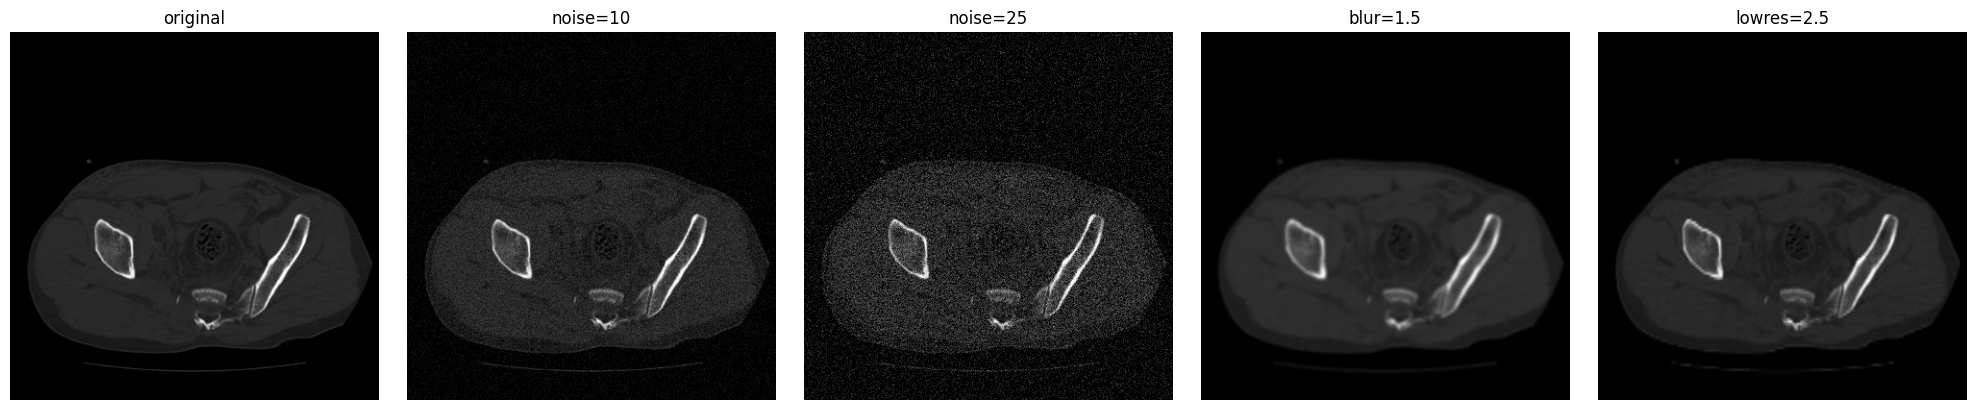

In [38]:
import sys, importlib, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "src")
import evaluate_volumes; importlib.reload(evaluate_volumes)
from build_case_cache import load_case_cache
from aumento_fisico import mm_por_pixel
caso = load_case_cache(CD, "019", canonical=True); k = len(caso["images"]) // 2
pruebas = ["", "noise=10", "noise=25", "blur=1.5", "lowres=2.5"]
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, p in zip(ax, pruebas):
    img = evaluate_volumes.apply_stress(caso["images"][k:k+1], caso["labels"][k:k+1], p, mm_por_pixel(caso))[0][0] if p else caso["images"][k]
    a.imshow(img, cmap="gray"); a.set_title(p or "original"); a.axis("off")
plt.tight_layout(); plt.savefig(f"{CARPETA}/ejemplos_ruido.png", dpi=90); plt.show()

Celda C: prueba de ruido, H7 contra H6 (unas 1.6 horas; muestra el avance caso por caso)

In [39]:
PRUEBAS = ["noise=10", "noise=25", "blur=1.5", "lowres=2.5"]
for etiqueta, ruta_m in [("H7", H7), ("H6", H6)]:
    for prueba in PRUEBAS:
        salida = f"{CARPETA}/ruido_{etiqueta}_{prueba.replace('=', '')}.json"
        if os.path.exists(salida):
            print("ya existe:", salida); continue
        print(f"\n===== {etiqueta} · {prueba} =====")
        !python src/evaluate_volumes.py --checkpoint "{ruta_m}" --cache-dir {CD} --split val --tta --stress {prueba} --output "{salida}" 2>&1 | grep -E "casos de|caso |Guardado|rror"

ya existe: /kaggle/working/resultados/ruido_H7_noise10.json
ya existe: /kaggle/working/resultados/ruido_H7_noise25.json
ya existe: /kaggle/working/resultados/ruido_H7_blur1.5.json
ya existe: /kaggle/working/resultados/ruido_H7_lowres2.5.json
ya existe: /kaggle/working/resultados/ruido_H6_noise10.json
ya existe: /kaggle/working/resultados/ruido_H6_noise25.json
ya existe: /kaggle/working/resultados/ruido_H6_blur1.5.json
ya existe: /kaggle/working/resultados/ruido_H6_lowres2.5.json


aporte de CBAM en H7, apagándolo (unos 12 minutos)

In [40]:
salida = f"{CARPETA}/cbam_H7_apagado.json"
if not os.path.exists(salida):
    !python src/evaluate_volumes.py --checkpoint "{H7}" --cache-dir {CD} --split val --tta --sin-cbam --output "{salida}" 2>&1 | grep -E "CBAM|casos de|caso |Guardado|rror"

CBAM apagado en 1 backbone(s)
15 casos de val | dispositivo cuda | TTA=True | segundo pase=False | normalizar=False
  1/15 caso 014: 298 cortes (38 s)
  2/15 caso 019: 350 cortes (81 s)
  3/15 caso 024: 350 cortes (124 s)
  4/15 caso 027: 313 cortes (163 s)
  5/15 caso 033: 365 cortes (210 s)
  6/15 caso 044: 409 cortes (261 s)
  7/15 caso 050: 326 cortes (302 s)
  8/15 caso 057: 341 cortes (344 s)
  9/15 caso 060: 333 cortes (386 s)
  10/15 caso 067: 369 cortes (431 s)
  11/15 caso 077: 350 cortes (473 s)
  12/15 caso 078: 388 cortes (521 s)
  13/15 caso 087: 312 cortes (560 s)
  14/15 caso 095: 257 cortes (592 s)
  15/15 caso 099: 286 cortes (627 s)
Guardado: /kaggle/working/resultados/cbam_H7_apagado.json


tablas (segundos; córrela cuando terminen C y D)

In [41]:
import glob, shutil
for f in glob.glob("/kaggle/working/H7_final_pengwin/val_H7_*.json") + glob.glob("/kaggle/input/**/val_H7_base.json", recursive=True):
    shutil.copy(f, CARPETA)
print(os.path.exists(f"{CARPETA}/val_H7_base.json"))

True


In [42]:
import json, pandas as pd
M = ["classification_f1_macro", "classification_auc_macro", "detection_map50", "detection_iou_mean",
     "segmentation_dice_macro", "instance_dice_matched"]
def leer(f): return json.load(open(f))["subsets"]["todo"]
H6_BASE = dict(classification_f1_macro=0.992, classification_auc_macro=0.999, detection_map50=0.971,
               detection_iou_mean=0.949, segmentation_dice_macro=0.971, instance_dice_matched=0.869)
h7 = leer(f"{CARPETA}/val_H7_base.json")
filas = [{"modelo": "H6 (EMA)", "prueba": "sin daño", **H6_BASE},
         {"modelo": "H7 (sin EMA)", "prueba": "sin daño", **{m: round(h7[m], 3) for m in M}}]
for et, nom in [("H6", "H6 (EMA)"), ("H7", "H7 (sin EMA)")]:
    for p in PRUEBAS:
        f = f"{CARPETA}/ruido_{et}_{p.replace('=', '')}.json"
        if os.path.exists(f): filas.append({"modelo": nom, "prueba": p, **{m: round(leer(f)[m], 3) for m in M}})
ruido = pd.DataFrame(filas).set_index(["prueba", "modelo"]); ruido.to_csv(f"{CARPETA}/tabla_ruido_H6_H7.csv")
display(ruido)

off = leer(f"{CARPETA}/cbam_H7_apagado.json")
cbam = pd.DataFrame([{"métrica": m, "H7 con CBAM": round(h7[m], 3), "H7 CBAM apagado": round(off[m], 3),
                      "caída": round(h7[m] - off[m], 3)} for m in M]).set_index("métrica")
cbam.to_csv(f"{CARPETA}/tabla_cbam_por_cabeza_H7.csv")
display(cbam)

classification_f1_macro  classification_auc_macro  \
prueba     modelo                                                            
sin daño   H6 (EMA)                        0.992                     0.999   
           H7 (sin EMA)                    0.992                     0.999   
noise=10   H6 (EMA)                        0.881                     0.982   
noise=25   H6 (EMA)                        0.691                     0.903   
blur=1.5   H6 (EMA)                        0.984                     0.999   
lowres=2.5 H6 (EMA)                        0.991                     0.999   
noise=10   H7 (sin EMA)                    0.879                     0.985   
noise=25   H7 (sin EMA)                    0.517                     0.901   
blur=1.5   H7 (sin EMA)                    0.982                     0.999   
lowres=2.5 H7 (sin EMA)                    0.990                     0.999   

                         detection_map50  detection_iou_mean  \
prueba     modelo                                              
sin daño   H6 (EMA)                0.971               0.949   
           H7 (sin EMA)            0.974               0.948   
noise=10   H6 (EMA)                0.690               0.677   
noise=25   H6 (EMA)                0.188               0.153   
blur=1.5   H6 (EMA)                0.961               0.920   
lowres=2.5 H6 (EMA)                0.973               0.943   
noise=10   H7 (sin EMA)            0.730               0.689   
noise=25   H7 (sin EMA)            0.224               0.231   
blur=1.5   H7 (sin EMA)            0.954               0.916   
lowres=2.5 H7 (sin EMA)            0.970               0.940   

                         segmentation_dice_macro  instance_dice_matched  
prueba     modelo                                                        
sin daño   H6 (EMA)                        0.971                  0.869  
           H7 (sin EMA)                    0.971                  0.873  
noise=10   H6 (EMA)                        0.889                  0.690  
noise=25   H6 (EMA)                        0.249                  0.135  
blur=1.5   H6 (EMA)                        0.937                  0.818  
lowres=2.5 H6 (EMA)                        0.961                  0.857  
noise=10   H7 (sin EMA)                    0.825                  0.654  
noise=25   H7 (sin EMA)                    0.383                  0.228  
blur=1.5   H7 (sin EMA)                    0.935                  0.819  
lowres=2.5 H7 (sin EMA)                    0.961                  0.861

,H7 con CBAM,H7 CBAM apagado,caída
métrica,,,
classification_f1_macro,0.992,0.444,0.549
classification_auc_macro,0.999,0.905,0.095
detection_map50,0.974,0.401,0.573
detection_iou_mean,0.948,0.281,0.667
segmentation_dice_macro,0.971,0.678,0.293
instance_dice_matched,0.873,0.461,0.412


descargar todo

In [43]:
import shutil
from IPython.display import FileLink
os.chdir("/kaggle/working")
shutil.make_archive("ruido_y_cbam_H7", "zip", CARPETA)
display(FileLink("ruido_y_cbam_H7.zip"))

/kaggle/working/ruido_y_cbam_H7.zip